# Lab 7 · SMS Spam Detection with a Bidirectional LSTM
### Deep Learning Laboratory (23DS5PCDLG)
**Name:** Kartikey Agrawal &nbsp;·&nbsp; **USN:** 1BM24CD028

Classify SMS messages as **spam** or **ham** using Embedding → Bidirectional LSTM → Dense (sigmoid).

**Dataset:** SMS Spam Collection, Almeida & Hidalgo, UCI Machine Learning Repository.

## Task 1 — Load and explore the dataset

In [1]:
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import TextVectorization, Embedding, LSTM, Bidirectional, Dense, Dropout
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

np.random.seed(42)
tf.random.set_seed(42)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [2]:
path = tf.keras.utils.get_file(
    "sms_spam.zip", "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip")
with zipfile.ZipFile(path) as z:
    with z.open("SMSSpamCollection") as f:
        df = pd.read_csv(f, sep="\t", names=["label", "message"])

print("Samples:", len(df))
print("Missing values:", df.isnull().sum().sum())
print(df["label"].value_counts())
df.head()

Samples: 5572
Missing values: 0
label
ham     4825
spam     747
Name: count, dtype: int64


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Length (chars) -> min: 2, max: 910, mean: 80.5

Ham : Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
Spam: Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's


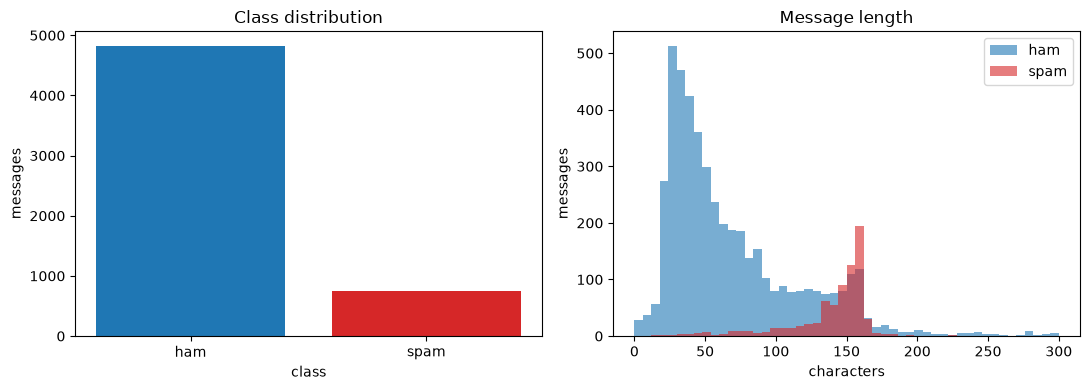

In [3]:
df["length"] = df["message"].str.len()
print(f"Length (chars) -> min: {df.length.min()}, max: {df.length.max()}, mean: {df.length.mean():.1f}")
print("\nHam :", df[df.label == "ham"].message.iloc[0])
print("Spam:", df[df.label == "spam"].message.iloc[0])

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
counts = df["label"].value_counts()
ax[0].bar(counts.index, counts.values, color=["tab:blue", "tab:red"])
ax[0].set_title("Class distribution"); ax[0].set_xlabel("class"); ax[0].set_ylabel("messages")
for lbl, col in [("ham", "tab:blue"), ("spam", "tab:red")]:
    ax[1].hist(df[df.label == lbl].length, bins=50, range=(0, 300), alpha=0.6, label=lbl, color=col)
ax[1].set_title("Message length"); ax[1].set_xlabel("characters"); ax[1].set_ylabel("messages"); ax[1].legend()
plt.tight_layout(); plt.show()

## Task 2 — Preprocess the text

In [4]:
words = df["message"].str.split().str.len()
print(f"Words per message -> mean: {words.mean():.1f}, 95th pct: {words.quantile(0.95):.0f}, "
      f"99th pct: {words.quantile(0.99):.0f}, max: {words.max()}")
print(f"Messages with <= 100 words: {(words <= 100).mean()*100:.2f}%")

Words per message -> mean: 15.6, 95th pct: 33, 99th pct: 55, max: 171
Messages with <= 100 words: 99.89%


**maxlen = 100:** almost every message is under 100 words, so little is truncated and padding stays small.

In [5]:
X = df["message"].values
y = (df["label"] == "spam").astype(int).values

X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=42)

vocab_size, maxlen = 10000, 100
vectorizer = TextVectorization(max_tokens=vocab_size, output_sequence_length=maxlen)
vectorizer.adapt(X_train)  # vocabulary from training data only

X_train = vectorizer(X_train)
X_val   = vectorizer(X_val)
X_test  = vectorizer(X_test)
print("X_train:", X_train.shape, " X_val:", X_val.shape, " X_test:", X_test.shape)
print(f"spam ratio: {y_train.mean():.3f} / {y_val.mean():.3f} / {y_test.mean():.3f}")

X_train: (4457, 100)  X_val: (557, 100)  X_test: (558, 100)
spam ratio: 0.134 / 0.133 / 0.134


## Task 3 — Build the model

In [6]:
model = Sequential([
    Input(shape=(maxlen,)),
    Embedding(vocab_size, 64),
    Bidirectional(LSTM(64)),
    Dropout(0.5),
    Dense(1, activation="sigmoid"),
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 706,177 (2.69 MB)

 Trainable params: 706,177 (2.69 MB)

 Non-trainable params: 0 (0.00 B)

**Why is the BiLSTM output 2 × units?** A forward and a backward LSTM (64 units each) are concatenated, giving 128.

## Task 4 — Train and evaluate

In [7]:
history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=8, batch_size=32)

Epoch 1/8


  1/140 ━━━━━━━━━━━━━━━━━━━━ 2:34 1s/step - accuracy: 0.4375 - loss: 0.6954

  6/140 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.7760 - loss: 0.6183

 11/140 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8097 - loss: 0.5368

 16/140 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8320 - loss: 0.4798

 21/140 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8363 - loss: 0.4547

... (233 outputs left out)

126/140 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9998 - loss: 0.0012

131/140 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9998 - loss: 0.0012

136/140 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9998 - loss: 0.0012

140/140 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9998 - loss: 0.0011 - val_accuracy: 0.9856 - val_loss: 0.0857


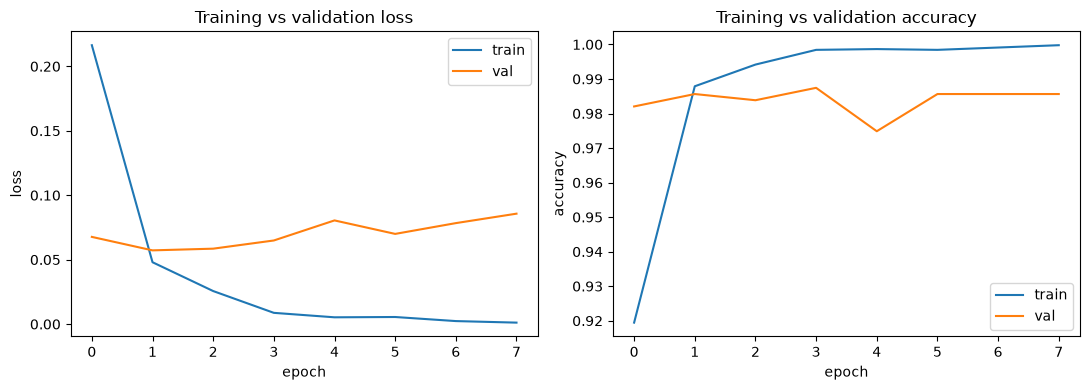

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for i, m in enumerate(["loss", "accuracy"]):
    ax[i].plot(history.history[m], label="train")
    ax[i].plot(history.history["val_" + m], label="val")
    ax[i].set_title(f"Training vs validation {m}"); ax[i].set_xlabel("epoch"); ax[i].set_ylabel(m); ax[i].legend()
plt.tight_layout(); plt.show()

Test accuracy: 99.10%


              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       483
        spam       1.00      0.93      0.97        75

    accuracy                           0.99       558
   macro avg       0.99      0.97      0.98       558
weighted avg       0.99      0.99      0.99       558



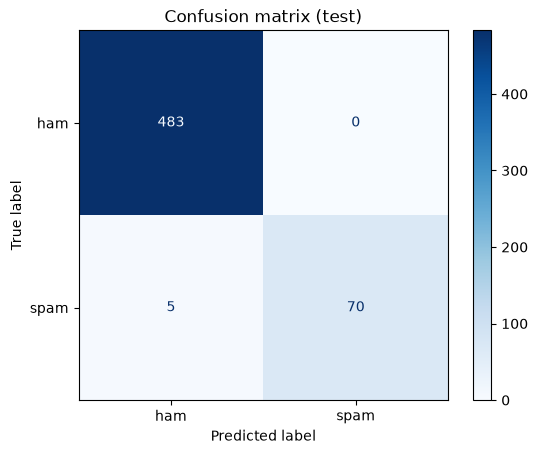

In [9]:
loss, acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {acc*100:.2f}%")

y_pred = (model.predict(X_test, verbose=0).ravel() >= 0.5).astype(int)
print(classification_report(y_test, y_pred, target_names=["ham", "spam"]))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["ham", "spam"], cmap="Blues")
plt.title("Confusion matrix (test)"); plt.show()

Only ~13% of messages are spam, so accuracy alone looks high even if spam is missed. Spam recall and the confusion matrix show how much spam is actually caught.

## Task 5 — Predict on new text

In [10]:
def predict(text):
    p = model.predict(vectorizer([text]), verbose=0)[0][0]
    return f"Spam ({p:.2f})" if p >= 0.5 else f"Ham ({1 - p:.2f})"

samples = [
    "WIN a free prize, text NOW to claim",
    "Congratulations! You have won a free iPhone. Click the link to claim now",
    "Are we meeting at the library at 5 today?",
    "Can you send me the notes from today's lecture",
    "URGENT: your account is suspended, call 0800123456 to reactivate",  # tricky
]
for s in samples:
    print(f"{predict(s):12s} <- {s}")

Spam (1.00)  <- WIN a free prize, text NOW to claim
Spam (1.00)  <- Congratulations! You have won a free iPhone. Click the link to claim now
Ham (1.00)   <- Are we meeting at the library at 5 today?
Ham (1.00)   <- Can you send me the notes from today's lecture
Ham (0.64)   <- URGENT: your account is suspended, call 0800123456 to reactivate


## Report

1. **Why padding?** A batch must be a fixed-shape tensor, so every message is padded/truncated to 100 tokens.
2. **Why embeddings beat one-hot?** Embeddings are small, dense and learned, so similar words get similar vectors; one-hot is huge, sparse and treats all words as unrelated.
3. **Why bidirectional?** It reads the message both ways, so each word gets context from before and after it.
4. **Output layer / loss:** binary task, so `Dense(1, 'sigmoid')` gives P(spam) with `binary_crossentropy`.
5. **Why accuracy misleads:** always predicting "ham" already gives ~87%, so we also used spam precision/recall/F1 and the confusion matrix.